## Домашнее задание. Теория вероятностей.

Выполнила: Рытикова Кирена

##### Подключение библиотек

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

#### 2. Симуляции в Python

##### Задание 2.1. Нормальная выборка

1. сгенерировать 5000 значений нормального распределения, например со средним 40 и стандартным отклонением 8
2. построить гистограмму и нарисовать поверх неё теоретическую плотность;
3. сравнить среднее и стандартное отклонение выборки с теми, что вы задали.

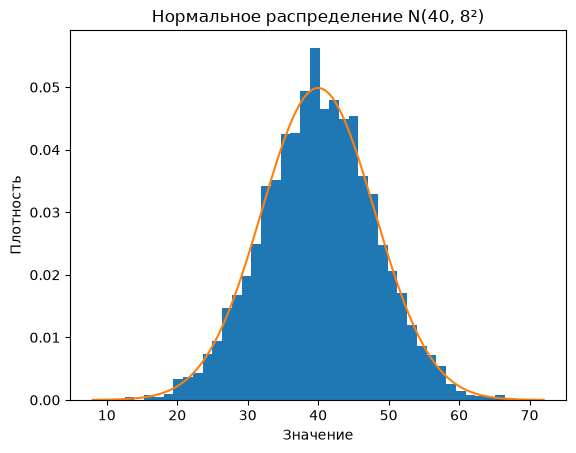

Заданные параметры: среднее = 40, стандартное отклонение = 8
Выборочное среднее = 40.111, выборочное стандартное отклонение = 7.910


In [2]:
mu, sigma = 40, 8

u = np.random.uniform(size=5000)
sample_normal = stats.norm.ppf(u, mu, sigma)

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample_normal, bins=40, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma))
plt.xlabel("Значение")
plt.ylabel("Плотность")
plt.title("Нормальное распределение N(40, 8²)")
plt.show()

print(f'Заданные параметры: среднее = {mu}, стандартное отклонение = {sigma}')
print(f'Выборочное среднее = {sample_normal.mean():.3f}, выборочное стандартное отклонение = {sample_normal.std(ddof=1):.3f}')


##### Задание 2.2. Биномиальная выборка

1. сгенерировать 5000 значений биномиального распределения, например n = 1000, p = 0,04;
2. построить гистограмму и нарисовать поверх неё теоретическую функцию вероятности;
3. сравнить среднее и стандартное отклонение выборки с теоретическими значениями.

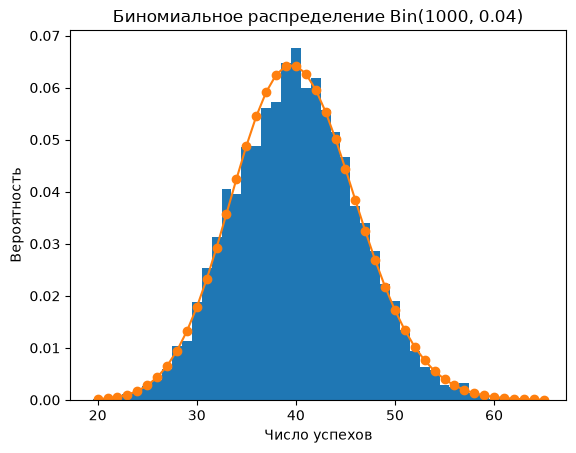

Теоретические значения: среднее = 40.000, стандартное отклонение = 6.197
Выборка: среднее = 40.057, стандартное отклонение = 6.217


In [3]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)

theory_mean = n * p
theory_variance = n * p * (1 - p)
theory_std = np.sqrt(theory_variance)

k = np.arange(sample.min(), sample.max() + 1)

plt.hist(sample, bins=k-0.5, density=True)
plt.plot(k, stats.binom.pmf(k, n, p), 'o-')
plt.xlabel("Число успехов")
plt.ylabel("Вероятность")
plt.title("Биномиальное распределение Bin(1000, 0.04)")
plt.show()

print(f"Теоретические значения: среднее = {theory_mean:.3f}, стандартное отклонение = {theory_std:.3f}")
print(f"Выборка: среднее = {sample.mean():.3f}, стандартное отклонение = {sample.std(ddof=1):.3f}")

##### Задание 2.3. ЦПТ на экспоненциальном распределении

1. сгенерировать выборку из 500 значений экспоненциального распределения и посчитать её
среднее;
2. повторить это несколько тысяч раз;
3. построить гистограмму полученных средних и в двух-трёх предложениях описать, что на ней
видно и почему.

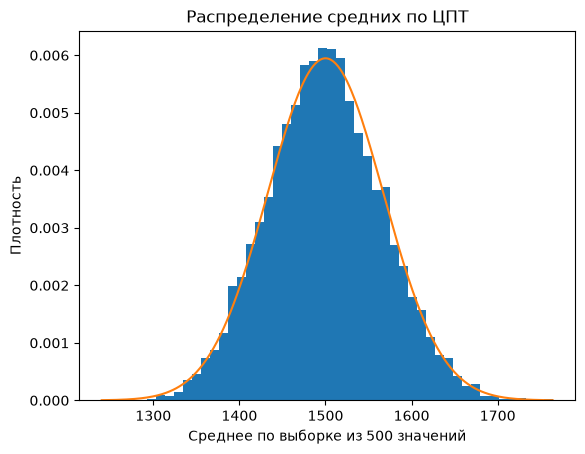

In [4]:
n_per_sample = 500
n_repetitions = 10000

sample_means = np.random.exponential(scale=1500, size=(n_repetitions, n_per_sample)).mean(axis=1)

standart_error = 1500 / np.sqrt(n_per_sample)
x = np.linspace(sample_means.min(), sample_means.max(), 400)
y = stats.norm.pdf(x, loc=1500, scale=standart_error)

plt.hist(sample_means, bins=50, density=True)
plt.plot(x, y)
plt.xlabel("Среднее по выборке из 500 значений")
plt.ylabel("Плотность")
plt.title("Распределение средних по ЦПТ")
plt.show()

На гистограмме средние имеют примерно колокообразную форму и сосредоточены около 1500. По ЦПТ среднее большого числа независимых наблюдений приближается к нормальному распределению, даже если исходные экспоненциальные значения асимметричны.

#### Задание 3. Мини-кейс про кнопку

##### Задание 3.1. Посчитать по формуле

1. для каждой группы посчитать, насколько может случайно ошибаться оценка конверсии (стандартную ошибку);
2. сравнить ошибку с разницей 0,3 п.п.;
3. написать предварительный вывод.

In [5]:
n_old = n_new = 5000 
clicks_old, clicks_new = 155, 170
p_old = clicks_old / n_old
p_new = clicks_new / n_new

se_old = np.sqrt(p_old * (1 - p_old) / n_old)
se_new = np.sqrt(p_new * (1 - p_new) / n_new)
difference = p_new - p_old
se_difference = np.sqrt(se_old**2 + se_new**2)

print(f"Старая кнопка: конверсия = {p_old:.2%}, SE = {se_old:.2%}")
print(f"Новая кнопка: конверсия = {p_new:.2%}, SE = {se_new:.2%}")
print(f"Разница = {difference*100:.2f} п.п.")
print(f"SE разницы = {se_difference*100:.2f} п.п.")

Старая кнопка: конверсия = 3.10%, SE = 0.25%
Новая кнопка: конверсия = 3.40%, SE = 0.26%
Разница = 0.30 п.п.
SE разницы = 0.35 п.п.


Наблюдаемая разница равна 0.3 п.п., что меньше одной стандартной ошибки разности (около 0.35 п.п.). 
Так как разница небольшая, пока нельзя уверенно сказать, что новая кнопка лучше.

##### Задание 3.2. Проверить симуляцией

1. предположить, что кнопка ни на что не влияет и конверсия в обеих группах одинаковая;
2. много раз смоделировать две такие группы по 5000 соискателей и посчитать разницу их
конверсий;
3. построить гистограмму разниц и посчитать, как часто случайно получается 0,3 п.п. или больше;
4. ответить: шум это или эффект.

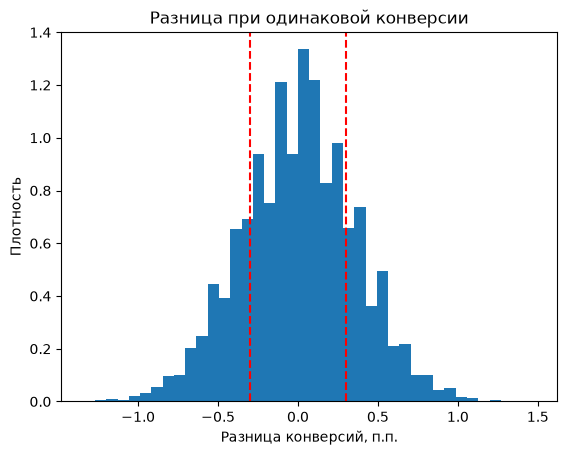

Доля симуляций с разницей 0,30 п.п. или больше: 0.404


In [6]:
common_conversion = (clicks_old + clicks_new) / (n_old + n_new)

old_clicks = np.random.binomial(n_old, common_conversion, size=10000)
new_clicks = np.random.binomial(n_new, common_conversion, size=10000)
differences = new_clicks / n_new - old_clicks / n_old

abs_difference = abs(difference) 
share_as_large = np.mean(np.abs(differences) >= abs_difference)

plt.hist(differences * 100, bins=40, density=True)
plt.axvline(-abs_difference * 100, color="red", linestyle="--")
plt.axvline(abs_difference * 100, color="red", linestyle="--")
plt.xlabel("Разница конверсий, п.п.")
plt.ylabel("Плотность")
plt.title("Разница при одинаковой конверсии")
plt.show()

print(f"Доля симуляций с разницей 0,30 п.п. или больше: {share_as_large:.3f}")

В симуляции разница не меньше 0.3 п.п. возникает примерно в 40% случаев. При одинаковой истинной конверсии разница такого размера нередко появляется из-за случайных колебаний. Нет оснований уверенно говорить об эффекте новой кнопки.

##### Задание 3.3. Выбросы во времени сессий

Время сессий за день, в минутах: 3, 4, 4, 5, 5, 6, 6, 7, 8, 52.
1. найти выбросы правилом трёх сигм;
2. найти выбросы по перцентилям;
3. сравнить результаты и объяснить, какой способ сработал лучше и почему

In [7]:
times = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

mean = times.mean()
sd = times.std(ddof=1)
outliers_3sigma = times[np.abs(times - mean) > 3*sd]

q1, q3 = np.percentile(times, [25, 75])
iqr = q3 - q1
outliers_iqr = times[(times < q1 - 1.5*iqr) | (times > q3 + 1.5*iqr)]

print("Выбросы по правилу трех сигм:", outliers_3sigma)
print("Выбросы по правилу IQR:", outliers_iqr)

Выбросы по правилу трех сигм: []
Выбросы по правилу IQR: [52]


Правило трёх сигм не находит выбросов: значение 52 увеличивает среднее и стандартное отклонение. 
Правило IQR выявило 52 как выброс, потому что оно опирается на квартили и меньше зависит от экстремальных значений. 
В данном случае лучше сработало правило IQR, так как 52 минуты явно отделяется от остальных значений, увеличия среднее и стандартное отклонение, из-за чего правило трех сигм ее не замечает. 